In [105]:
import pandas as pd
import polars as pl
from datetime import datetime, timedelta
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, accuracy_score, precision_score,roc_curve, auc,mean_squared_error,
precision_recall_curve,log_loss,roc_auc_score,average_precision_score,f1_score)
from sklearn.model_selection import train_test_split,RepeatedKFold,cross_val_score,TimeSeriesSplit,GridSearchCV
from tqdm import tqdm
from sklearn.preprocessing import StandardScaler,MinMaxScaler,RobustScaler,OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.base import clone
from sklearn.calibration import calibration_curve
import xgboost as xgb

In [106]:

data = pl.DataFrame() 
years = ["2016","2017","2018","2019","2021","2022","2023","2024","2025","2026"]

for y in years:
    PATH = f"../data/processed/statcast_{y}.parquet"
    data = pl.concat([data, pl.read_parquet(PATH)], how="diagonal_relaxed")

In [107]:
top20_ids = (
    data.group_by("pitcher")
        .agg(pl.len().alias("pitches"))
        .sort("pitches", descending=True)
        .head(20)
)

In [108]:
data = data.filter(pl.col("description").is_in(["called_strike"]) & 
                    pl.col("pitcher").is_in(top20_ids["pitcher"]) &
                (pl.col("plate_x").is_not_null()) &
                (pl.col("sz_top").is_not_null())
                )


C:\Users\mmcdo\AppData\Local\Temp\ipykernel_27668\1081205181.py:1: DeprecationWarning: `is_in` with a collection of the same datatype is ambiguous and deprecated.
Please use `implode` to return to previous behavior.

See https://github.com/pola-rs/polars/issues/22149 for more information.
  data = data.filter(pl.col("description").is_in(["called_strike"]) &


In [109]:
data = data.to_pandas()

In [110]:
pitch_mapping = {
    # Fastballs (Velocity & Movement variations)
    "FF": "Fastball",  # Four-Seam Fastball
    "SI": "Fastball",  # Sinker
    "FC": "Fastball",  # Cutter
    "FA": "Fastball",  # Other Fastball

    # Sliders (Horizontal movement)
    "SL": "Slider",    # TSlider
    "ST": "Slider",    # Sweeper
    "SV": "Slider",    # Slurve

    # Curveballs
    "CU": "Curveball", # Traditional Curveball
    "KC": "Curveball", # Knuckle-Curve
    "CS": "Curveball", # Slow Curve

    # Changeups
    "CH": "Changeup",  # Traditional Changeup
    "FS": "Changeup",  # Splitter (Finger-Split)
    "FO": "Changeup",  # Forkball
    "SC": "Changeup",  # Screwball (Fades opposite of a slider)

    # Junk
    "EP": "Junk",      # Eephus (Ultra-slow utility pitch)
    "KN": "Junk"       # Knuckleball
}

data["pitch_cat"] = data["pitch_type"].map(pitch_mapping)
data["count"] = data["balls"].astype(str) + "-" + data["strikes"].astype(str)
data["same_hand"] = (data["stand"] == data["p_throws"]).astype(int)
data["wrong_call"] = data["is_missed_ball"] | data["is_missed_strike"]
data['call'] = data['description']
data["month"] = pd.to_datetime(data["game_date"]).dt.month
data["zone"] = data["zone"].astype(int).astype(str) 
data["pitcher"] = data["pitcher"].astype(int).astype(str) 
data["batter"] = data["batter"].astype(int).astype(str) 
data["called_strike"] = (data["description"] == "called_strike").astype(int)

In [111]:
#data.info(verbose=True)

In [112]:
feature_cols = [
    "release_speed",
    "release_spin_rate",
    "pitch_cat",
    "zone",
    "balls",
    "strikes",
    "inning",
    "outs_when_up",
    "inning_topbot",
    "stand",
    #"p_throws",
    "n_thruorder_pitcher",
    "sz_top",
    "sz_bot",
    "called_strike",
    #"pitcher",
    #"batter",
    "pitch_number",
    "pitcher_days_since_prev_game"

]

response_col = [
    "is_missed_ball",
    #"is_missed_strike",
    #"wrong_call"
    ][0]

In [113]:
cat_cols = ["pitch_cat", "zone", "inning_topbot", "stand", "p_throws","pitcher","batter",]
for c in cat_cols:
    data[c] = data[c].astype("category")
num_cols = [c for c in feature_cols if c not in cat_cols]

In [114]:
cv = TimeSeriesSplit(n_splits=5)

xgb_model = xgb.XGBClassifier(
    random_state=6740,
    objective="binary:logistic",
    enable_categorical=True,
    tree_method="hist",
    eval_metric="aucpr",
    scale_pos_weight=2.0 
)
pipe = Pipeline(steps=[("xgb", xgb_model)])

param_grid = {
    "xgb__n_estimators":  [100, 200],
    "xgb__learning_rate": [0.05, 0.1],
    "xgb__max_depth":     [2, 3],
    "xgb__gamma":         [0, 1],
    "xgb__reg_lambda":    [1.0, 5.0],
     "xgb__min_child_weight": [5, 20]
}

results, test_frames, train_frames = [], [], []
top_pitchers = [str(p) for p in top20_ids["pitcher"]]

for p in top_pitchers:
    df = data[data["pitcher"] == p].reset_index(drop=True)

    for c in cat_cols:
        df[c] = df[c].astype("category")

    split = int(len(df) * 0.85)
    train, test = df.iloc[:split], df.iloc[split:]

    if len(train) < 200 or train[response_col].nunique() < 2:
        print(f"skip pitcher {p}: n_train={len(train)}, y-unique={train[response_col].nunique()}")
        continue

    search = GridSearchCV(pipe, param_grid, cv=cv,
                          scoring="average_precision", n_jobs=-1)
    search.fit(train[feature_cols], train[response_col])
    print(f"{p}: best={search.best_params_}  cv_ap={search.best_score_:.4f}")

592332: best={'xgb__gamma': 0, 'xgb__learning_rate': 0.05, 'xgb__max_depth': 3, 'xgb__min_child_weight': 20, 'xgb__n_estimators': 100, 'xgb__reg_lambda': 1.0}  cv_ap=0.7941
605400: best={'xgb__gamma': 0, 'xgb__learning_rate': 0.05, 'xgb__max_depth': 2, 'xgb__min_child_weight': 5, 'xgb__n_estimators': 100, 'xgb__reg_lambda': 5.0}  cv_ap=0.7746
571578: best={'xgb__gamma': 1, 'xgb__learning_rate': 0.1, 'xgb__max_depth': 3, 'xgb__min_child_weight': 5, 'xgb__n_estimators': 200, 'xgb__reg_lambda': 1.0}  cv_ap=0.7942
543037: best={'xgb__gamma': 1, 'xgb__learning_rate': 0.05, 'xgb__max_depth': 3, 'xgb__min_child_weight': 5, 'xgb__n_estimators': 100, 'xgb__reg_lambda': 5.0}  cv_ap=0.7609
434378: best={'xgb__gamma': 1, 'xgb__learning_rate': 0.1, 'xgb__max_depth': 2, 'xgb__min_child_weight': 5, 'xgb__n_estimators': 200, 'xgb__reg_lambda': 5.0}  cv_ap=0.7738
453286: best={'xgb__gamma': 0, 'xgb__learning_rate': 0.05, 'xgb__max_depth': 2, 'xgb__min_child_weight': 20, 'xgb__n_estimators': 100, 'xgb__

In [116]:
model = search.best_estimator_

p_tr = model.predict_proba(train[feature_cols])[:, 1]
p_te = model.predict_proba(test[feature_cols])[:, 1]

pr, rc, th = precision_recall_curve(train[response_col], p_tr)
target_recall = 0.75
idx = np.argmin(np.abs(rc[:-1] - target_recall)) 
thr_p = th[idx]

results.append({
    "pitcher":        p,
    "n_train":        len(train),
    "n_test":         len(test),
    "base_rate_test": test[response_col].mean(),
    "cv_ap":          search.best_score_,
    "test_ap":        average_precision_score(test[response_col], p_te),
    "test_auc":       roc_auc_score(test[response_col], p_te),
    "test_ll":        log_loss(test[response_col], p_te),
    "thr":            thr_p,
    **{k.replace("xgb__", ""): v for k, v in search.best_params_.items()},
})

train_frames.append(train.assign(pred_prob=p_tr, thr=thr_p, split="train"))
test_frames.append( test.assign(pred_prob=p_te, thr=thr_p, split="test"))

print(f"{p}:  n_train={len(train):>5}  n_test={len(test):>4}  "
        f"cv_ap={search.best_score_:.4f}  test_ap={results[-1]['test_ap']:.4f}")

results_df = pd.DataFrame(results).sort_values("test_ap", ascending=False)
display(results_df)

640455:  n_train= 3009  n_test= 531  cv_ap=0.7596  test_ap=0.6720


,pitcher,n_train,n_test,base_rate_test,cv_ap,test_ap,test_auc,test_ll,thr,gamma,learning_rate,max_depth,min_child_weight,n_estimators,reg_lambda
0,640455,3009,531,0.224105,0.759604,0.672001,0.805448,0.396797,0.39136,1,0.05,3,5,100,1.0


In [117]:
all_train = pd.concat(train_frames, ignore_index=True)
all_test  = pd.concat(test_frames,  ignore_index=True)

all_train["pred_label"] = (all_train["pred_prob"] >= all_train["thr"]).astype(int)
all_test ["pred_label"] = (all_test ["pred_prob"] >= all_test ["thr"]).astype(int)

def _metrics(y, p, l, tag):
    print(f"{tag:6s} LogLoss {log_loss(y, p):.4f} | "
          f"ROC-AUC {roc_auc_score(y, p):.4f} | "
          f"PR-AUC {average_precision_score(y, p):.4f} | "
          f"F1 {f1_score(y, l):.4f} | base rate {y.mean():.3f}")

_metrics(all_train[response_col], all_train["pred_prob"], all_train["pred_label"], "Train")
_metrics(all_test [response_col], all_test ["pred_prob"], all_test ["pred_label"], "Test")


results = pd.DataFrame({
    "actual":     all_test[response_col].values,
    "pred_prob":  all_test["pred_prob"].values,
    "pred_label": all_test["pred_label"].values,
    "split":      "test",
})

Train  LogLoss 0.3848 | ROC-AUC 0.8682 | PR-AUC 0.8122 | F1 0.6610 | base rate 0.291
Test   LogLoss 0.3968 | ROC-AUC 0.8054 | PR-AUC 0.6720 | F1 0.5428 | base rate 0.224


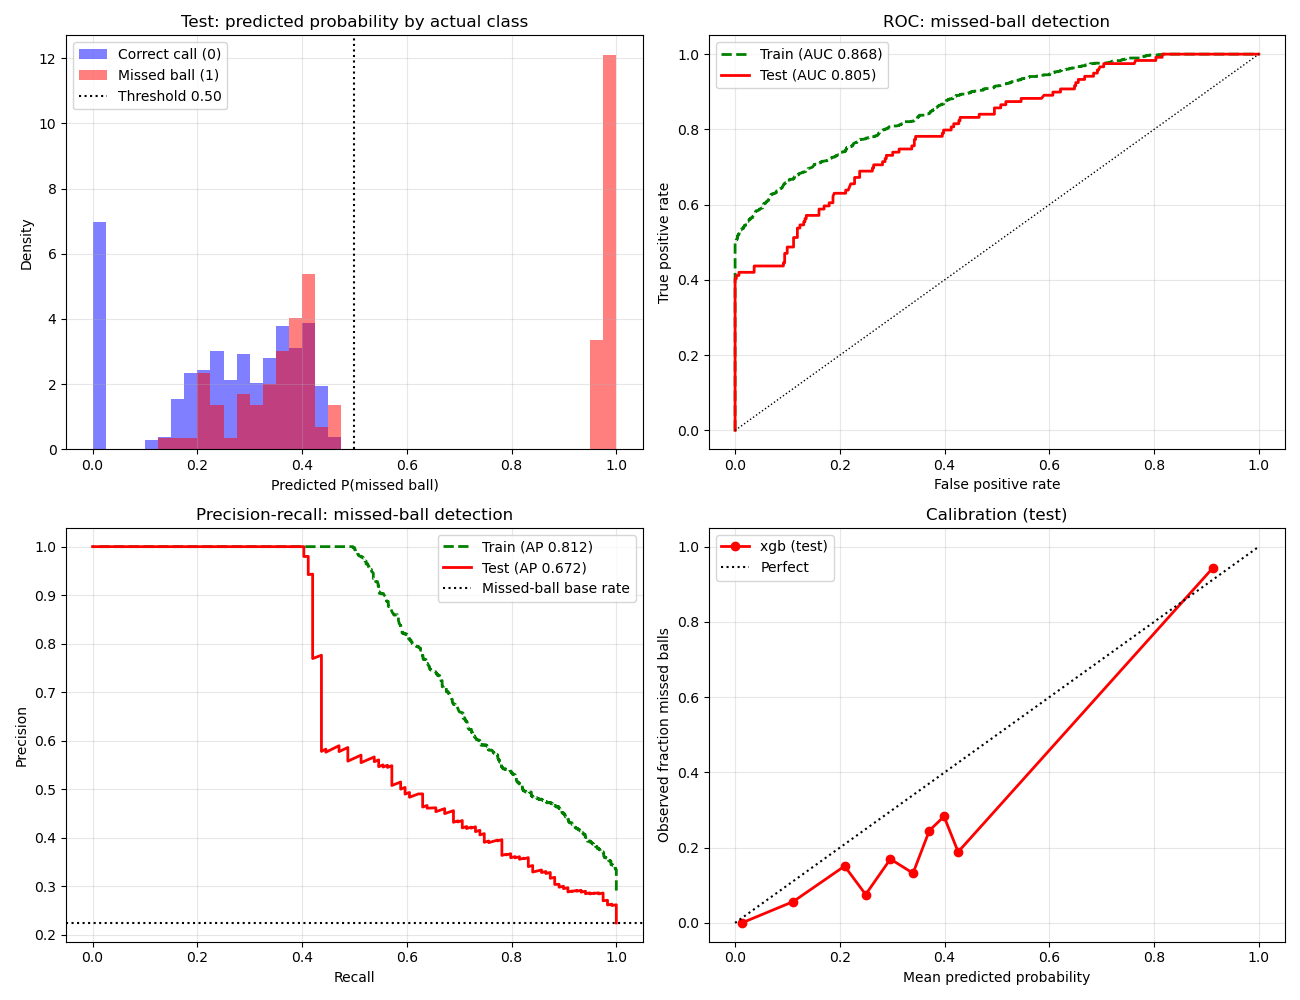

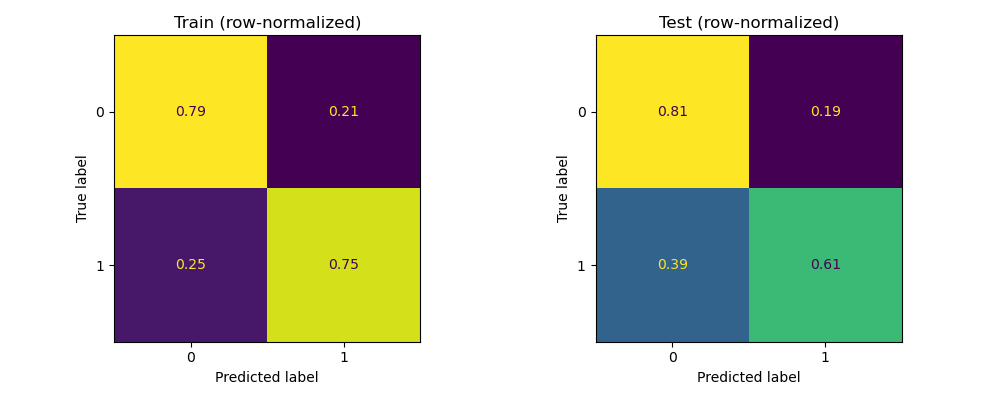

In [118]:
%matplotlib widget
fig, ax = plt.subplots(2, 2, figsize=(13, 10))
thr = 0.5
bins = np.linspace(0, 1, 41)
for cls, c, lbl in [(0, 'b', 'Correct call (0)'), (1, 'r', 'Missed ball (1)')]:
    ax[0, 0].hist(all_test["pred_prob"][all_test[response_col].values == cls], bins=bins, color=c, alpha=.5, density=True, label=lbl)
ax[0, 0].axvline(thr, color='black', linestyle=':', linewidth=1.5, label=f'Threshold {thr:.2f}')
ax[0, 0].set(xlabel='Predicted P(missed ball)', ylabel='Density', title='Test: predicted probability by actual class')
ax[0, 0].legend()

for yt, pp, st, lbl in [(all_train[response_col], all_train["pred_prob"], 'g--', 'Train'), (all_test[response_col], all_test["pred_prob"], 'r-', 'Test')]:
    f, t, _ = roc_curve(yt, pp)
    ax[0, 1].plot(f, t, st, linewidth=2, label=f'{lbl} (AUC {roc_auc_score(yt, pp):.3f})')
ax[0, 1].plot([0, 1], [0, 1], 'k:', linewidth=1)
ax[0, 1].set(xlabel='False positive rate', ylabel='True positive rate', title='ROC: missed-ball detection'); ax[0, 1].legend()

for yt, pp, st, lbl in [(all_train[response_col], all_train["pred_prob"], 'g--', 'Train'), (all_test[response_col], all_test["pred_prob"], 'r-', 'Test')]:
    p_, r_, _ = precision_recall_curve(yt, pp)
    ax[1, 0].plot(r_, p_, st, linewidth=2, label=f'{lbl} (AP {average_precision_score(yt, pp):.3f})')
ax[1, 0].axhline(all_test[response_col].mean(), color='black', linestyle=':', linewidth=1.5, label='Missed-ball base rate')
ax[1, 0].set(xlabel='Recall', ylabel='Precision', title='Precision-recall: missed-ball detection'); ax[1, 0].legend()

fp, mp = calibration_curve(all_test[response_col], all_test["pred_prob"], n_bins=10, strategy='quantile')
ax[1, 1].plot(mp, fp, 'ro-', linewidth=2, label='xgb (test)')
ax[1, 1].plot([0, 1], [0, 1], 'k:', linewidth=1.5, label='Perfect')
ax[1, 1].set(xlabel='Mean predicted probability', ylabel='Observed fraction missed balls', title='Calibration (test)')
ax[1, 1].legend()

for a in ax.ravel(): a.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../figs/xgb_MissedBalls_Diagnostics.png", dpi=300)
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, yt, pl, ttl in [(ax[0], all_train[response_col], all_train["pred_label"], 'Train'), (ax[1], all_test[response_col], all_test["pred_label"], 'Test')]:
    ConfusionMatrixDisplay.from_predictions(yt, pl, ax=a, colorbar=False, normalize='true', values_format='.2f')
    a.set_title(f'{ttl} (row-normalized)')
plt.tight_layout()
plt.savefig("../figs/xgb_MissedBalls_Confusion.png", dpi=300)
plt.show()